In [ ]:
!pip install torch torchvision matplotlib pillow torchmetrics

In [ ]:
import os
import zipfile
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import urllib.request

from PIL import Image
from torchvision import transforms
from google.colab import files
from torchmetrics.image import PeakSignalNoiseRatio
from torchmetrics.image import StructuralSimilarityIndexMeasure


In [ ]:
from google.colab import files
import zipfile
import os

uploaded = files.upload()

zip_name = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_name, "r") as zip_ref:
    zip_ref.extractall()

print(os.listdir())

Saving 16_images.zip to 16_images.zip
['.config', 'test_images', '__MACOSX', '16_images.zip', 'test_images.zip', '16_images', 'sample_data']


In [ ]:
TAESD_BASE_URL = "https://raw.githubusercontent.com/madebyollin/taesd/main"
TAESD_FILES = ["taesd.py", "taesd_encoder.pth", "taesd_decoder.pth"]

for fname in TAESD_FILES:
    if not os.path.exists(fname):
        print("Downloading:", fname)
        urllib.request.urlretrieve(f"{TAESD_BASE_URL}/{fname}", fname)

from taesd import TAESD

Downloading: taesd.py
Downloading: taesd_encoder.pth
Downloading: taesd_decoder.pth


In [ ]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

taesd = TAESD(
    encoder_path="taesd_encoder.pth",
    decoder_path="taesd_decoder.pth"
).to(DEVICE)

taesd.eval()

Device: cpu


TAESD(
  (encoder): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): Block(
      (conv): Sequential(
        (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU()
        (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (3): ReLU()
        (4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      )
      (skip): Identity()
      (fuse): ReLU()
    )
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (3): Block(
      (conv): Sequential(
        (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU()
        (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (3): ReLU()
        (4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      )
      (skip): Identity()
      (fuse): ReLU()
    )
    (4): Block(
      (conv): Sequential(
       

Yardımcı fonksiyonlar

In [ ]:
to_tensor = transforms.ToTensor()

def load_images(folder):
    image_files = []
    for fname in sorted(os.listdir(folder)):
        if fname.lower().endswith((".jpg", ".jpeg", ".png", ".webp")):
            image_files.append(os.path.join(folder, fname))

    images = []
    for path in image_files:
        img = Image.open(path).convert("RGB")
        img = to_tensor(img)
        images.append(img)

    images = torch.stack(images)
    return images, image_files

def show_image(tensor, title=""):
    # tensor shape: [3, H, W]
    img = tensor.detach().cpu().permute(1, 2, 0).clamp(0, 1)
    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.title(title)
    plt.axis("off")
    plt.show()

def show_compare(original, reconstructed, title=""):
    original = original.detach().cpu().permute(1, 2, 0).clamp(0, 1)
    reconstructed = reconstructed.detach().cpu().permute(1, 2, 0).clamp(0, 1)

    plt.figure(figsize=(8, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(original)
    plt.title("Original")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(reconstructed)
    plt.title("Reconstructed")
    plt.axis("off")

    plt.suptitle(title)
    plt.show()



In [ ]:
x_64, image_files = load_images(TEST_DIR)

print("Image count:", len(x_64))
print("Tensor shape:", x_64.shape)




Image count: 16
Tensor shape: torch.Size([16, 3, 64, 64])


# Deney 1 — 16 tane 64×64 görselden tek bir 256×256 kolaj oluşturma

Collage shape: torch.Size([3, 256, 256])


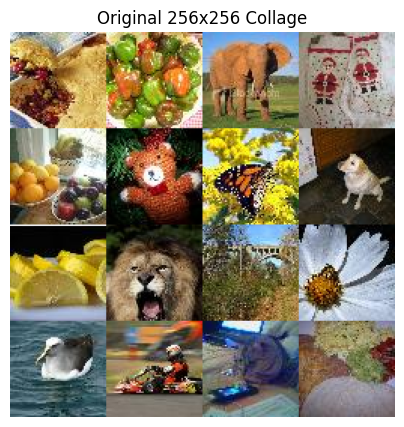

In [ ]:
x_64 = x_64[:16]

rows = []

for i in range(4):
    row_images = []

    for j in range(4):
        index = i * 4 + j
        row_images.append(x_64[index])

    row = torch.cat(row_images, dim=2)
    rows.append(row)

collage_256 = torch.cat(rows, dim=1)

print("Collage shape:", collage_256.shape)
show_image(collage_256, "Original 256x256 Collage")

In [ ]:


psnr = PeakSignalNoiseRatio(data_range=1.0).to(DEVICE)
ssim = StructuralSimilarityIndexMeasure(data_range=1.0).to(DEVICE)

PSNR : 17.2720 dB
SSIM : 0.4018


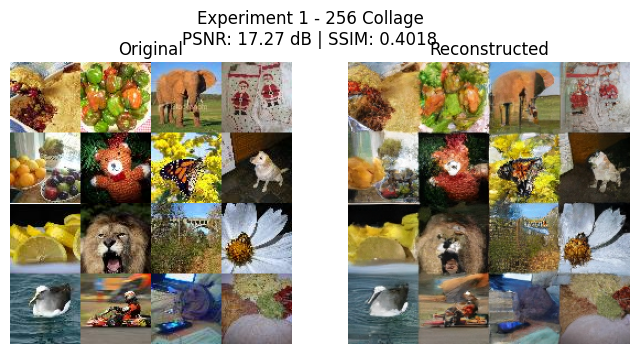

In [ ]:
with torch.no_grad():

    x = collage_256.unsqueeze(0).to(DEVICE)   # [1, 3, 256, 256]

    latent = taesd.encoder(x)

    recon_256 = taesd.decoder(latent)

    recon_256 = recon_256.clamp(0, 1)

    psnr_score = psnr(recon_256, x).item()
    ssim_score = ssim(recon_256, x).item()

    recon_256 = recon_256.cpu().squeeze(0)

print(f"PSNR : {psnr_score:.4f} dB")
print(f"SSIM : {ssim_score:.4f}")

show_compare(
    collage_256,
    recon_256,
    f"Experiment 1 - 256 Collage\nPSNR: {psnr_score:.2f} dB | SSIM: {ssim_score:.4f}"
)

# Deney 2 — 64×64 → 256×256 → TAESD → 256×256 → 64×64

In [ ]:
upsample = nn.Upsample(
    size=(256, 256),
    mode="bilinear",
    align_corners=False
)

downsample = nn.Upsample(
    size=(64, 64),
    mode="bilinear",
    align_corners=False
)

In [ ]:
recons_64 = []
psnr_scores = []
ssim_scores = []

with torch.no_grad():
    for i in range(len(x_64)):

        original_64 = x_64[i:i+1].to(DEVICE)

        up_256 = upsample(original_64)

        latent = taesd.encoder(up_256)
        recon_256 = taesd.decoder(latent).clamp(0, 1)

        recon_64 = downsample(recon_256).clamp(0, 1)

        psnr_score = psnr(recon_64, original_64).item()
        ssim_score = ssim(recon_64, original_64).item()

        psnr_scores.append(psnr_score)
        ssim_scores.append(ssim_score)

        recons_64.append(recon_64.cpu().squeeze(0))

recons_64 = torch.stack(recons_64)

print("Reconstructed shape:", recons_64.shape)
print(f"Mean PSNR: {sum(psnr_scores) / len(psnr_scores):.4f} dB")
print(f"Mean SSIM: {sum(ssim_scores) / len(ssim_scores):.4f}")

Reconstructed shape: torch.Size([16, 3, 64, 64])
Mean PSNR: 26.0829 dB
Mean SSIM: 0.8894


In [ ]:
print("\n--- Image Results ---")

for i in range(len(x_64)):

    original = x_64[i:i+1].to(DEVICE)
    reconstructed = recons_64[i:i+1].to(DEVICE)

    psnr_score = psnr(reconstructed, original).item()
    ssim_score = ssim(reconstructed, original).item()

    print(f"Image {i+1} | PSNR: {psnr_score:.4f} dB | SSIM: {ssim_score:.4f}")


--- Image Results ---
Image 1 | PSNR: 24.2424 dB | SSIM: 0.8665
Image 2 | PSNR: 23.9785 dB | SSIM: 0.8702
Image 3 | PSNR: 27.9267 dB | SSIM: 0.9157
Image 4 | PSNR: 25.7220 dB | SSIM: 0.8980
Image 5 | PSNR: 26.6161 dB | SSIM: 0.9153
Image 6 | PSNR: 24.3653 dB | SSIM: 0.8233
Image 7 | PSNR: 20.3522 dB | SSIM: 0.8241
Image 8 | PSNR: 29.6436 dB | SSIM: 0.9119
Image 9 | PSNR: 28.9486 dB | SSIM: 0.9355
Image 10 | PSNR: 26.3527 dB | SSIM: 0.8951
Image 11 | PSNR: 23.2202 dB | SSIM: 0.8069
Image 12 | PSNR: 24.9964 dB | SSIM: 0.8862
Image 13 | PSNR: 27.9887 dB | SSIM: 0.9286
Image 14 | PSNR: 25.0916 dB | SSIM: 0.9227
Image 15 | PSNR: 29.1665 dB | SSIM: 0.9243
Image 16 | PSNR: 28.7150 dB | SSIM: 0.9058


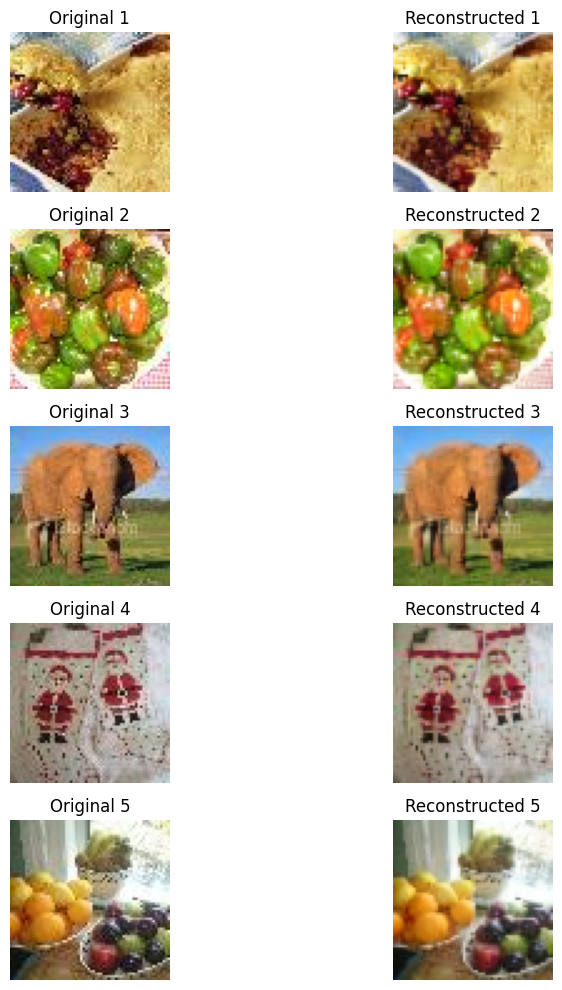

In [ ]:
plt.figure(figsize=(10,10))

for i in range(5):

    plt.subplot(5,2,2*i+1)
    plt.imshow(x_64[i].permute(1,2,0))
    plt.title(f"Original {i+1}")
    plt.axis("off")

    plt.subplot(5,2,2*i+2)
    plt.imshow(recons_64[i].permute(1,2,0))
    plt.title(f"Reconstructed {i+1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

# Deney 3 — 64×64 → 512×512 → TAESD → 512×512 → 64×64

In [ ]:
upsample = nn.Upsample(
    size=(512, 512),
    mode="bilinear",
    align_corners=False
)

downsample = nn.Upsample(
    size=(64, 64),
    mode="bilinear",
    align_corners=False
)

In [ ]:
recons_64 = []
psnr_scores = []
ssim_scores = []

with torch.no_grad():
    for i in range(len(x_64)):

        original_64 = x_64[i:i+1].to(DEVICE)

        up_256 = upsample(original_64)

        latent = taesd.encoder(up_256)
        recon_256 = taesd.decoder(latent).clamp(0, 1)

        recon_64 = downsample(recon_256).clamp(0, 1)

        psnr_score = psnr(recon_64, original_64).item()
        ssim_score = ssim(recon_64, original_64).item()

        psnr_scores.append(psnr_score)
        ssim_scores.append(ssim_score)

        recons_64.append(recon_64.cpu().squeeze(0))

recons_64 = torch.stack(recons_64)

print("Reconstructed shape:", recons_64.shape)
print(f"Mean PSNR: {sum(psnr_scores) / len(psnr_scores):.4f} dB")
print(f"Mean SSIM: {sum(ssim_scores) / len(ssim_scores):.4f}")

Reconstructed shape: torch.Size([16, 3, 64, 64])
Mean PSNR: 31.1199 dB
Mean SSIM: 0.9705


In [ ]:
print("\n--- Image Results ---")

for i in range(len(x_64)):

    original = x_64[i:i+1].to(DEVICE)
    reconstructed = recons_64[i:i+1].to(DEVICE)

    psnr_score = psnr(reconstructed, original).item()
    ssim_score = ssim(reconstructed, original).item()

    print(f"Image {i+1} | PSNR: {psnr_score:.4f} dB | SSIM: {ssim_score:.4f}")


--- Image Results ---
Image 1 | PSNR: 29.9881 dB | SSIM: 0.9713
Image 2 | PSNR: 28.8596 dB | SSIM: 0.9645
Image 3 | PSNR: 31.2190 dB | SSIM: 0.9745
Image 4 | PSNR: 30.6666 dB | SSIM: 0.9807
Image 5 | PSNR: 30.3190 dB | SSIM: 0.9730
Image 6 | PSNR: 31.4224 dB | SSIM: 0.9619
Image 7 | PSNR: 26.7868 dB | SSIM: 0.9640
Image 8 | PSNR: 33.8213 dB | SSIM: 0.9623
Image 9 | PSNR: 32.9225 dB | SSIM: 0.9273
Image 10 | PSNR: 33.3759 dB | SSIM: 0.9812
Image 11 | PSNR: 29.8553 dB | SSIM: 0.9687
Image 12 | PSNR: 30.5987 dB | SSIM: 0.9770
Image 13 | PSNR: 32.1190 dB | SSIM: 0.9800
Image 14 | PSNR: 30.5201 dB | SSIM: 0.9792
Image 15 | PSNR: 33.5377 dB | SSIM: 0.9819
Image 16 | PSNR: 31.9065 dB | SSIM: 0.9800


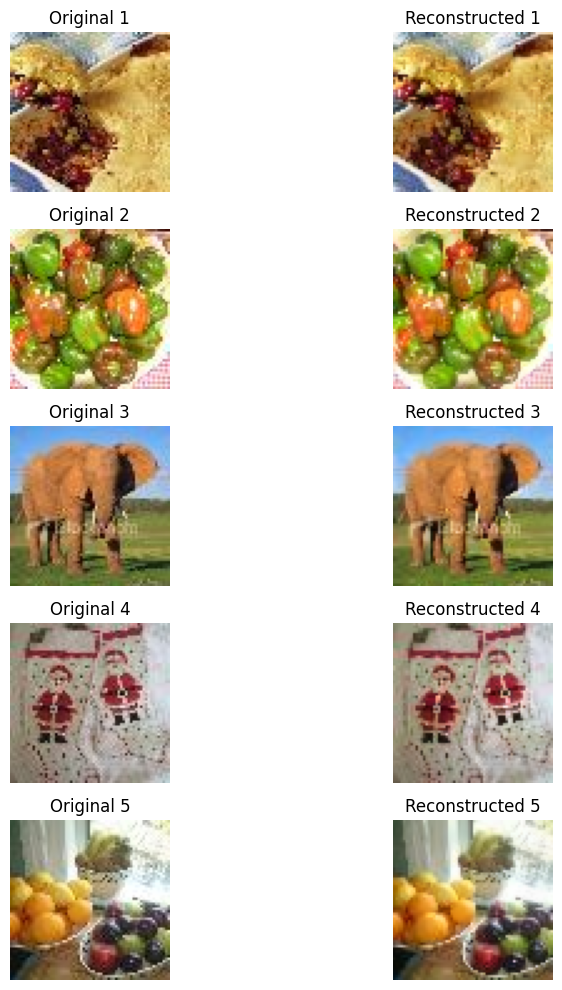

In [ ]:
plt.figure(figsize=(10,10))

for i in range(5):

    plt.subplot(5,2,2*i+1)
    plt.imshow(x_64[i].permute(1,2,0))
    plt.title(f"Original {i+1}")
    plt.axis("off")

    plt.subplot(5,2,2*i+2)
    plt.imshow(recons_64[i].permute(1,2,0))
    plt.title(f"Reconstructed {i+1}")
    plt.axis("off")

plt.tight_layout()
plt.show()